## Step 4: Which genes are different?

This notebook runs the three comparisons from step 3 and asks, for every gene, whether its activity is different between the two groups.

For each gene I do three things.

- **Fold change.** The difference in average activity between the groups. The data is on a log2 scale, so a difference of 1 means the gene is twice as active in one group, and a difference of 2 means four times as active. A positive number always means higher in the more aggressive group (IDH wild-type, or glioblastoma).
- **A test.** Welch's t-test asks whether the difference is bigger than what chance alone would give. I picked it because it works well with groups of different sizes and different spread.
- **A correction.** With about 20,000 genes, some would look different by pure luck. The Benjamini-Hochberg correction, the same one I used in Project 3, adjusts for this. The adjusted number is called the FDR. An FDR of 0.05 means about 5 in 100 of the genes I call different are expected to be false alarms.

A gene counts as **different** if its FDR is below 0.05 and its fold change is at least 1 in either direction. With groups this big, tiny differences can pass the test but not matter much biologically, so the fold change cutoff keeps the list to genes that changed a lot.

There is also an **age check**. IDH wild-type patients are about 20 years older than IDH mutant patients, so some differences could be about age and not the tumor. For each comparison I rerun the test with age and sex taken into account, and I note which genes still hold up.

In [11]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)

plt.rcParams["font.size"] = 20

purple = "#F26D5B"
dark_blue = "#7DB9E8"
light_purple = "#F28DB2"

Path("csv").mkdir(exist_ok=True)
Path("figures").mkdir(exist_ok=True)

data_dir = Path.home() / "Desktop" / "PROJECT_4_PORT"
def nice(name):
    return name if name.startswith("IDH") else name.lower()

print("Done")

Done


In [12]:
#Load what the earlier steps saved
patient_table = pd.read_csv("csv/patient_groups.csv")
log_expr = pd.read_csv(data_dir / "processed" / "expression_log2.csv.gz", index_col=0)
log_expr = log_expr[patient_table["PATIENT_ID"]]

print("Patients:", len(patient_table))
print("Genes:", log_expr.shape[0])

Patients: 667
Genes: 20511


### The correction and the comparison function
The first function is the Benjamini-Hochberg correction. The second runs one comparison from start to finish. It takes the name of the group column, the group that should come out as the positive side, and the group it is compared against.

Inside it, the age and sex check fits a straight-line model for every gene at once, with the group, age and sex as inputs. The number it reports for the group is the difference that is left after age and sex are accounted for.

In [13]:
def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)
    n = len(p_values)
    order = np.argsort(p_values)
    adjusted = p_values[order] * n / np.arange(1, n + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    result = np.empty(n)
    result[order] = np.minimum(adjusted, 1)
    return result


def run_comparison(column, group, baseline):
    rows = patient_table[patient_table[column].isin([group, baseline])]
    in_group = rows["PATIENT_ID"][rows[column] == group]
    in_baseline = rows["PATIENT_ID"][rows[column] == baseline]

    a = log_expr[in_group].to_numpy()
    b = log_expr[in_baseline].to_numpy()
    with np.errstate(all="ignore"):
        t_stat, p_value = stats.ttest_ind(a, b, axis=1, equal_var=False)
    p_value = np.where(np.isfinite(p_value), p_value, 1.0)

    result = pd.DataFrame({"gene": log_expr.index,
                           "mean_group": a.mean(axis=1),
                           "mean_baseline": b.mean(axis=1),
                           "log2_fold_change": a.mean(axis=1) - b.mean(axis=1),
                           "p_value": p_value})
    result["fdr"] = benjamini_hochberg(result["p_value"])
    result["different"] = (result["fdr"] < 0.05) & (result["log2_fold_change"].abs() >= 1)

    # age and sex check, using only patients with both values
    adj = rows.dropna(subset=["AGE", "SEX"])
    y = log_expr[adj["PATIENT_ID"]].to_numpy().T
    x = np.column_stack([np.ones(len(adj)),
                         (adj[column] == group).astype(float),
                         adj["AGE"].astype(float),
                         (adj["SEX"] == "Male").astype(float)])
    xtx_inv = np.linalg.inv(x.T @ x)
    beta = xtx_inv @ x.T @ y
    residuals = y - x @ beta
    dof = len(adj) - x.shape[1]
    variance = (residuals ** 2).sum(axis=0) / dof
    with np.errstate(all="ignore"):
        t_adjusted = beta[1] / np.sqrt(variance * xtx_inv[1, 1])
    p_adjusted = 2 * stats.t.sf(np.abs(t_adjusted), dof)
    p_adjusted = np.where(np.isfinite(p_adjusted), p_adjusted, 1.0)

    result["log2_fold_change_adjusted"] = beta[1]
    result["fdr_adjusted"] = benjamini_hochberg(p_adjusted)
    result["holds_up_after_age_sex"] = (result["different"]
                                        & (result["fdr_adjusted"] < 0.05)
                                        & (np.sign(result["log2_fold_change_adjusted"]) == np.sign(result["log2_fold_change"])))

    result = result.sort_values("p_value").reset_index(drop=True)
    return result, len(in_group), len(in_baseline), len(adj)

print("Done")

Done


### Run the three comparisons
A positive fold change means higher in IDH wild-type for A and B, and higher in glioblastoma for C. 

In [14]:
comparisons = {
    "A": ("compare_A", "IDH wild-type", "IDH mutant", "IDH wild-type versus IDH mutant, everyone"),
    "B": ("compare_B", "IDH wild-type", "IDH mutant", "IDH wild-type versus IDH mutant, lower grade only"),
    "C": ("compare_C", "Glioblastoma", "Lower grade", "Glioblastoma versus lower grade, IDH wild-type only"),
}

results = {}
summary_rows = []
for key, (column, group, baseline, title) in comparisons.items():
    result, n_group, n_baseline, n_adjusted = run_comparison(column, group, baseline)
    results[key] = result
    result.to_csv("csv/de_" + key + ".csv", index=False)
    different = result[result["different"]]
    summary_rows.append({"comparison": key,
                         "patients_group": n_group,
                         "patients_baseline": n_baseline,
                         "genes_tested": len(result),
                         "different": len(different),
                         "higher_in_group": int((different["log2_fold_change"] > 0).sum()),
                         "higher_in_baseline": int((different["log2_fold_change"] < 0).sum()),
                         "hold_up_after_age_sex": int(result["holds_up_after_age_sex"].sum())})

summary = pd.DataFrame(summary_rows).set_index("comparison")
print(summary.to_string())
print()
print("Higher in group means higher in IDH wild-type (A and B) or glioblastoma (C).")

            patients_group  patients_baseline  genes_tested  different  higher_in_group  higher_in_baseline  hold_up_after_age_sex
comparison                                                                                                                        
A                      234                426         20511       3486             2104                1382                   3485
B                       94                417         20511       2441             1643                 798                   2441
C                      140                 94         20511       1617              668                 949                   1615

Higher in group means higher in IDH wild-type (A and B) or glioblastoma (C).


### Volcano plots
Each dot is a gene. Left to right is the fold change, and height is how strong the evidence is (higher means a smaller FDR). Genes in the top corners are both strongly different and statistically solid. Purple dots are genes that are higher in the more aggressive group, and dark blue dots are genes that are lower. Gray dots did not pass the cutoffs.

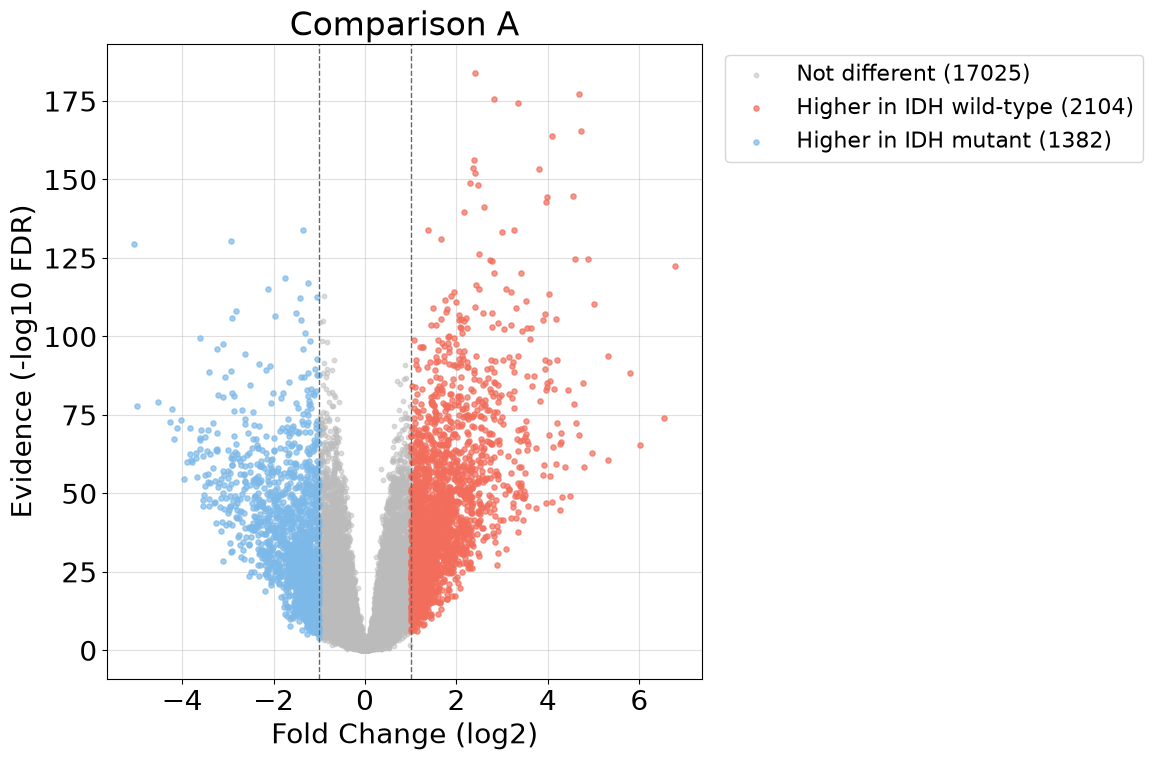

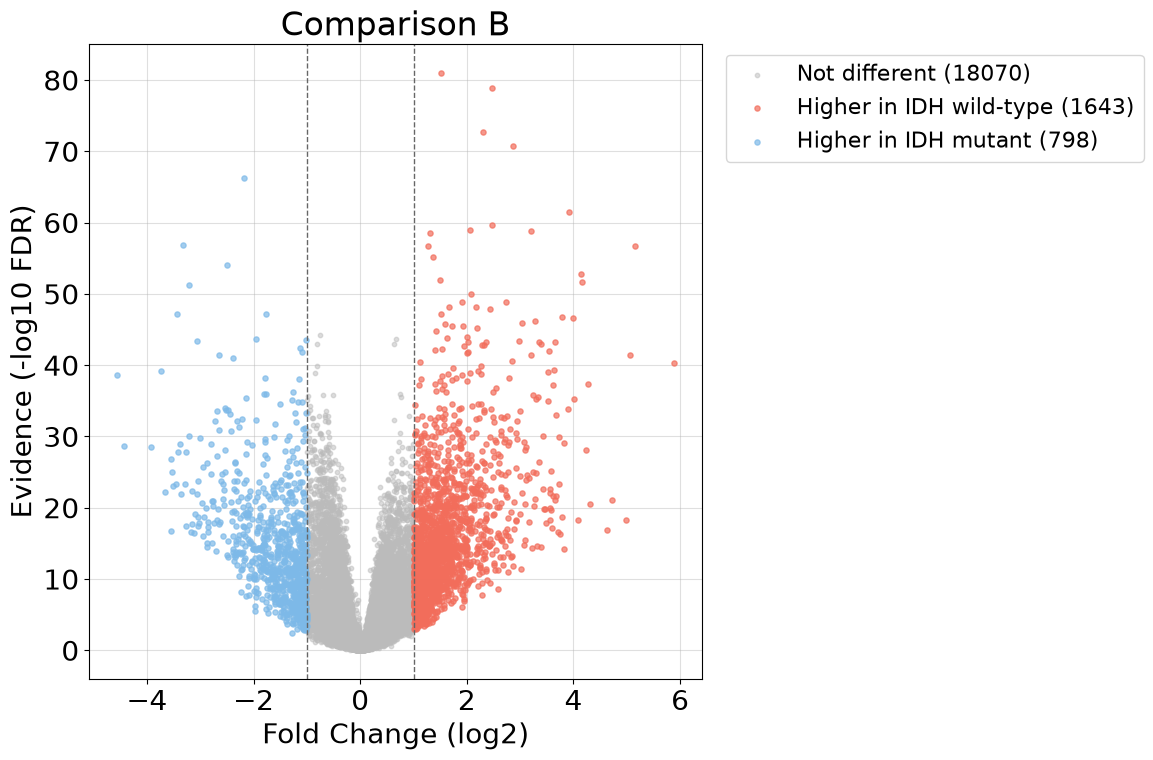

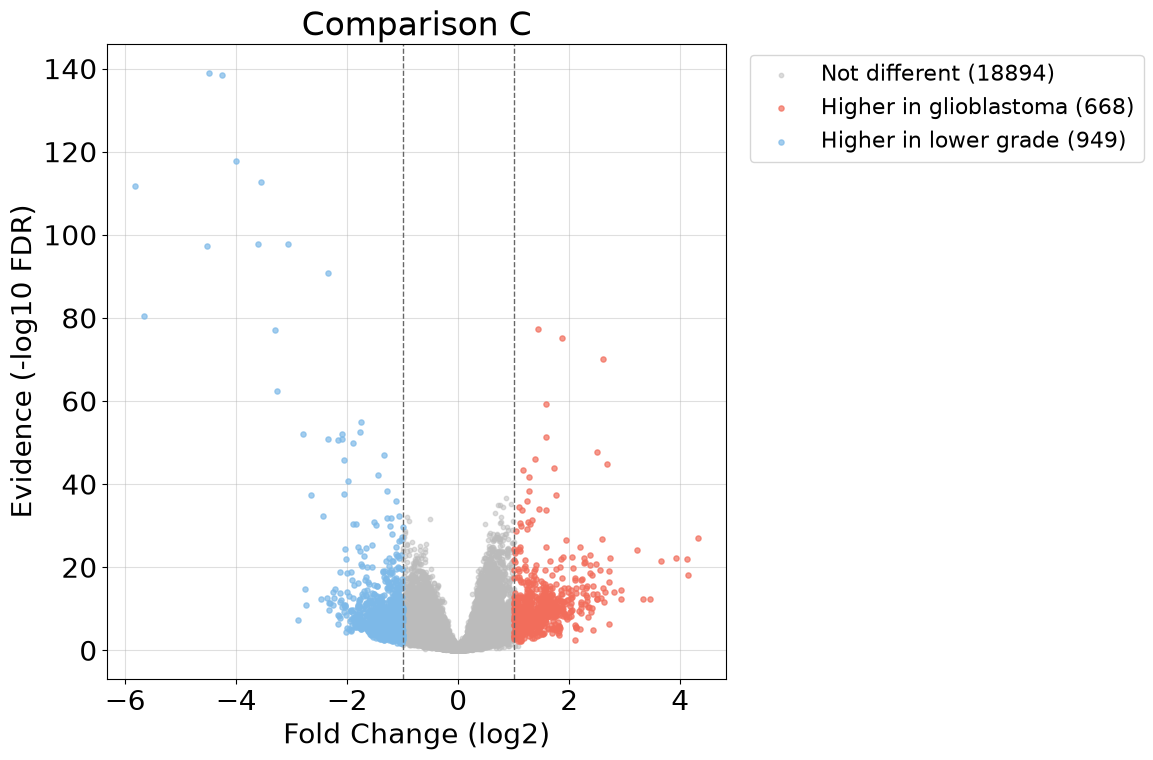

In [15]:
for key, (column, group, baseline, title) in comparisons.items():
    result = results[key]
    fdr = np.maximum(result["fdr"].to_numpy(), 1e-300)
    height = -np.log10(fdr)
    up = result["different"] & (result["log2_fold_change"] > 0)
    down = result["different"] & (result["log2_fold_change"] < 0)
    rest = ~result["different"]

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.scatter(result.loc[rest, "log2_fold_change"], height[rest], c=grey, s=10, alpha=0.5, label="Not different (" + str(int(rest.sum())) + ")")
    ax.scatter(result.loc[up, "log2_fold_change"], height[up], c=purple, s=14, alpha=0.7, label="Higher in " + nice(group) + " (" + str(int(up.sum())) + ")")
    ax.scatter(result.loc[down, "log2_fold_change"], height[down], c=dark_blue, s=14, alpha=0.7, label="Higher in " + nice(baseline) + " (" + str(int(down.sum())) + ")")
    ax.axvline(1, color="#666666", linestyle="--", linewidth=1)
    ax.axvline(-1, color="#666666", linestyle="--", linewidth=1)
    ax.set_title("Comparison " + key)
    ax.set_xlabel("Fold Change (log2)")
    ax.set_ylabel("Evidence (-log10 FDR)")
    ax.grid(True, alpha=0.4)
    ax.set_axisbelow(True)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=16)
    plt.tight_layout()
    plt.savefig("figures/p4-volcano-" + key + ".png", dpi=150, bbox_inches="tight")
    plt.show()

### The biggest changes
For each comparison, the ten genes with the largest fold change in each direction, out of the genes that passed the cutoffs.

In [16]:
for key, (column, group, baseline, title) in comparisons.items():
    different = results[key][results[key]["different"]]
    print("Comparison " + key + ": " + title)
    print()
    print("Most higher in " + nice(group) + ":")
    print(different.nlargest(10, "log2_fold_change")[["gene", "log2_fold_change", "fdr"]].to_string(index=False))
    print()
    print("Most higher in " + nice(baseline) + ":")
    print(different.nsmallest(10, "log2_fold_change")[["gene", "log2_fold_change", "fdr"]].to_string(index=False))
    print()
    print()

Comparison A: IDH wild-type versus IDH mutant, everyone

Most higher in IDH wild-type:
   gene  log2_fold_change           fdr
 CHI3L1          6.784451 4.520330e-123
  POSTN          6.548562  1.326214e-74
    LTF          6.022253  3.908001e-66
  MEOX2          5.792393  5.146310e-89
PLA2G2A          5.322345  3.422648e-61
  SHOX2          5.314882  1.638680e-94
  MOXD1          4.998627 5.098915e-111
 HOXC10          4.955511  1.034073e-63
   AQP5          4.877314 2.755591e-125
  HOXA7          4.796283  4.337178e-59

Most higher in IDH mutant:
  gene  log2_fold_change           fdr
 PRLHR         -5.050281 4.362685e-130
 KLRC2         -4.989085  2.094628e-78
 CSMD3         -4.529861  8.031312e-80
PCDH15         -4.267892  2.645325e-73
SPHKAP         -4.228659  1.517829e-77
  HMX1         -4.180644  5.991509e-68
 SMOC1         -4.122151  1.535311e-71
 HPSE2         -4.015394  6.097680e-74
  IRX2         -3.949478  3.663754e-55
 SFRP2         -3.887530  1.064586e-60


Comparison B: 

### Sanity check with genes we already know about
CHI3L1, EGFR and MKI67 are known to be more active in aggressive glioma, so they should show a positive fold change in A and B. IDH1 is the gene that carries the mutation, but the mutation changes the protein and not how active the gene is, so IDH1 should not change much.

In [17]:
known = ["CHI3L1", "EGFR", "MKI67", "IDH1"]
check = pd.DataFrame(index=known)
for key in results:
    table = results[key].set_index("gene")
    check["fold_change_" + key] = table["log2_fold_change"].reindex(known).round(2)
    check["fdr_" + key] = table["fdr"].reindex(known)
print(check.to_string())

        fold_change_A          fdr_A  fold_change_B         fdr_B  fold_change_C         fdr_C
CHI3L1           6.78  4.520330e-123           5.89  5.811057e-41           1.61  6.370917e-06
EGFR             1.02   7.288221e-08           0.91  6.705449e-03           0.18  7.030763e-01
MKI67            1.11   2.917009e-11           0.49  1.342611e-01           1.10  6.349067e-04
IDH1             0.59   6.413257e-20           0.13  2.209027e-01           0.77  1.334424e-10


### Which genes show up in both A and B?
These are the most trustworthy IDH genes. They are different when using everyone (A) and also when only looking at lower grade tumors (B), where glioblastoma is not part of the story.

In [18]:
a_up = set(results["A"].query("different and log2_fold_change > 0")["gene"])
a_down = set(results["A"].query("different and log2_fold_change < 0")["gene"])
b_up = set(results["B"].query("different and log2_fold_change > 0")["gene"])
b_down = set(results["B"].query("different and log2_fold_change < 0")["gene"])

both_up = sorted(a_up & b_up)
both_down = sorted(a_down & b_down)
only_a = (a_up | a_down) - (b_up | b_down)

print("Different in A:", len(a_up | a_down))
print("Different in B:", len(b_up | b_down))
print("Different in both, higher in IDH wild-type:", len(both_up))
print("Different in both, higher in IDH mutant:", len(both_down))
print("Different in A only (could be about glioblastoma, not IDH):", len(only_a))

pd.DataFrame({"gene": both_up + both_down,
              "direction": ["Higher in IDH wild-type"] * len(both_up) + ["Higher in IDH mutant"] * len(both_down)}
             ).to_csv("csv/de_A_and_B_shared.csv", index=False)
print("Saved csv/de_A_and_B_shared.csv")

Different in A: 3486
Different in B: 2441
Different in both, higher in IDH wild-type: 1449
Different in both, higher in IDH mutant: 738
Different in A only (could be about glioblastoma, not IDH): 1298
Saved csv/de_A_and_B_shared.csv


In [19]:
suspects = results["C"].query("different and log2_fold_change < 0").nsmallest(12, "log2_fold_change")["gene"].tolist()

four_groups = {
    "IDH mutant, lower grade": (patient_table["idh_group"] == "IDH mutant") & (patient_table["tumor_type"] == "Lower grade"),
    "IDH wild-type, lower grade": (patient_table["idh_group"] == "IDH wild-type") & (patient_table["tumor_type"] == "Lower grade"),
    "IDH wild-type, glioblastoma": (patient_table["idh_group"] == "IDH wild-type") & (patient_table["tumor_type"] == "Glioblastoma"),
    "IDH mutant, glioblastoma": (patient_table["idh_group"] == "IDH mutant") & (patient_table["tumor_type"] == "Glioblastoma"),
}

table = pd.DataFrame({name: log_expr.loc[suspects, patient_table.loc[mask, "PATIENT_ID"]].mean(axis=1)
                      for name, mask in four_groups.items()}).round(2)
print("Average activity (log2) of the biggest lower grade genes in Comparison C")
print(table.to_string())
print()

name_pattern = r"^LOC\d+|P\d+$"
for key in results:
    different = results[key][results[key]["different"]]
    odd = different["gene"].str.contains(name_pattern, regex=True)
    print("Comparison " + key + ":", int(odd.sum()), "of", len(different), "different genes have a LOC or pseudogene style name") 

Average activity (log2) of the biggest lower grade genes in Comparison C
             IDH mutant, lower grade  IDH wild-type, lower grade  IDH wild-type, glioblastoma  IDH mutant, glioblastoma
Hugo_Symbol                                                                                                            
FTHL3                           8.19                        8.28                         2.46                      2.34
HSPB1P1                         6.00                        7.54                         1.87                      1.21
LOC644936                       4.86                        5.26                         0.72                      0.68
LOC643387                       5.24                        5.40                         0.92                      0.88
NACAP1                          6.96                        6.41                         2.15                      2.31
HNRNPA1P33                      6.11                        5.46                       

In [20]:
name_pattern = r"^LOC\d+|P\d+$"
for key in results:
    results[key]["pseudogene_style_name"] = results[key]["gene"].str.contains(name_pattern, regex=True)

# in comparison C, flag genes that go from clearly active in lower grade to nearly off in glioblastoma
c = results["C"]
c["near_off_in_glioblastoma"] = (c["mean_group"] <= 3) & (c["mean_baseline"] >= 6)
c["cleaner_hit"] = c["different"] & ~c["pseudogene_style_name"] & ~c["near_off_in_glioblastoma"]

print("Comparison C, genes called different:", int(c["different"].sum()))
print("  With a LOC or pseudogene style name:", int((c["different"] & c["pseudogene_style_name"]).sum()))
print("  Nearly off in glioblastoma:", int((c["different"] & c["near_off_in_glioblastoma"]).sum()))
print("  Left after removing both:", int(c["cleaner_hit"].sum()))
print()

cleaner = c[c["cleaner_hit"]]
print("Most higher in lower grade, after cleaning:")
print(cleaner.nsmallest(10, "log2_fold_change")[["gene", "log2_fold_change", "fdr"]].to_string(index=False))
print()
print("Most higher in glioblastoma, after cleaning:")
print(cleaner.nlargest(10, "log2_fold_change")[["gene", "log2_fold_change", "fdr"]].to_string(index=False))

for key in results:
    results[key].to_csv("csv/de_" + key + ".csv", index=False)
print()
print("Saved the csv files again with the new flag columns")

Comparison C, genes called different: 1617
  With a LOC or pseudogene style name: 127
  Nearly off in glioblastoma: 5
  Left after removing both: 1488

Most higher in lower grade, after cleaning:
    gene  log2_fold_change          fdr
SLC6A10P         -3.259449 3.372561e-63
 PPIAL4C         -3.059564 1.544892e-98
  OPALIN         -2.891269 6.324629e-08
   AIFM3         -2.762734 2.230275e-15
  GABRG1         -2.739948 1.434046e-11
   CDC26         -2.659291 3.818412e-38
     TNR         -2.477424 5.708246e-13
 LGALS9C         -2.434099 4.156659e-33
 SLC22A6         -2.363729 2.840155e-13
    RELN         -2.323873 1.764454e-10

Most higher in glioblastoma, after cleaning:
   gene  log2_fold_change          fdr
    CA9          4.322406 1.220094e-27
   IBSP          4.128036 1.095095e-22
    PI3          3.925798 8.003886e-23
    IL8          3.652982 2.627592e-22
PLA2G2A          3.447211 5.183495e-13
   SAA1          3.323128 4.762106e-13
  TREM1          3.228606 7.950122e-25
   ESM